In [1]:
'''
Santa 2026 | Verified Frontier 128,212

Replay the public portfolio and pinned local improvements and export the verified submission.
'''

In [2]:
'''
Credits

Public baseline (128,215 instructions) and triwalk engine: goodpjw2008.
https://www.kaggle.com/code/goodpjw2008/santa-2026-fresh-program-re-search-lb-128-215
https://www.kaggle.com/datasets/goodpjw2008/santa-2026-dag-lns-programs/versions/293

The pinned replacement programs were found in our local triwalk runs.
The exact referee builds on Ertuğrul Özer's Starter Notebook.
https://www.kaggle.com/code/ozertuu/santa-2026-starter-notebook
'''

# Santa 2026 · Verified Frontier

**128,212 arithmetic instructions across 1,000 puzzles.** This notebook pins the 128,215-instruction public portfolio and applies verified local replacements, replays every instruction on the 48-register calculator and exports a checked submission.

| What the audit measures | Why it matters |
|:---|:---|
| Instruction cost by puzzle size | Shows where portfolio improvements can move the total |
| Operation mix | Describes how the current programs compute their targets |
| Exact replay | Verifies every target, arithmetic operation and register index |

The figures use the verified programs from this run.

The Apache-licensed public baseline is embedded as a compressed, checksum-verified snapshot. The Kaggle run requires only the competition input, so a mutable dataset mount cannot replace version 293.

## 1 · Inputs and configuration

In [5]:
import csv
import hashlib
import os
import json
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
from statistics import median
from tempfile import TemporaryDirectory
from time import perf_counter


COMPETITION = 'santa-2026'
DATASET_OWNER = 'goodpjw2008'
DATASET_SLUG = 'santa-2026-dag-lns-programs'
PORTFOLIO_SHA256 = 'e89c2e747a93482078db34423dd494ae5a953ba77d63d6d0921a858b9eb3d754'
EXPECTED_SCORE = 128_212
SUBMISSION_COLUMNS = ['id', 'program']
MAX_INSTRUCTIONS = 4_096
MAX_PROGRAM_BYTES = 131_072

Instruction = tuple[str, int, int, int]
Program = tuple[Instruction, ...]


@dataclass(frozen=True)
class Config:
    puzzles_csv: Path
    output_csv: Path

    @classmethod
    def discover(cls) -> 'Config':
        kaggle = Path('/kaggle/input')
        if kaggle.is_dir():
            puzzles = cls.locate(kaggle, COMPETITION, 'puzzles.csv')
            return cls(puzzles, Path('/kaggle/working/submission.csv'))

        data = Path(os.environ.get('SANTA_DATA_DIR', 'data'))
        return cls(data / 'puzzles.csv',
                   Path(os.environ.get('SANTA_OUTPUT_CSV', 'submission.csv')))

    @staticmethod
    def locate(root: Path, slug: str, filename: str) -> Path:
        matches = [path for path in root.rglob(filename) if slug in path.parent.parts]
        if len(matches) != 1:
            raise FileNotFoundError(
                f'Expected one {slug}/{filename} input, found {len(matches)}'
            )
        return matches[0]

    def check_inputs(self) -> None:
        if not self.puzzles_csv.is_file():
            raise FileNotFoundError(
                f'Attach the {COMPETITION} competition data or copy puzzles.csv '
                f'to {self.puzzles_csv}'
            )

In [ ]:
'''
Embed the public baseline because importing a notebook can mount a newer
dataset version even when the notebook declares a pinned version ID.
'''
import base64
import lzma


PUBLIC_PORTFOLIO_XZ = (
    '...'
)

def pinned_portfolio() -> bytes:
    raw = lzma.decompress(base64.b64decode(PUBLIC_PORTFOLIO_XZ, validate=True))
    if hashlib.sha256(raw).hexdigest() != PORTFOLIO_SHA256:
        raise ValueError('The embedded version 293 snapshot failed its checksum')
    return raw


## 2 · Exact calculator and program profile

In [7]:
@dataclass(frozen=True)
class Puzzle:
    starts: tuple[int, ...]
    targets: frozenset[int]
    value_limit: int
    register_count: int

    @classmethod
    def from_row(cls, row: dict[str, str]) -> 'Puzzle':
        return cls(
            tuple(json.loads(row['starting_values'])),
            frozenset(json.loads(row['targets'])),
            int(row['value_limit']),
            int(row['registers']),
        )


@dataclass(frozen=True)
class ProgramProfile:
    length: int
    operations: Counter[str]
    peak_value: int
    populated_registers: int


class Calculator:
    '''Read both sources before writing and remember targets across overwrites.'''

    def replay(self, puzzle: Puzzle, program: Program) -> ProgramProfile:
        if len(program) > MAX_INSTRUCTIONS:
            raise ValueError('Program exceeds the instruction limit')

        registers = list(puzzle.starts) + [None] * (
            puzzle.register_count - len(puzzle.starts)
        )
        missing = set(puzzle.targets).difference(puzzle.starts)
        operations = Counter()
        peak_value = max(puzzle.starts, default=0)

        for number, instruction in enumerate(program, start=1):
            if len(instruction) != 4:
                raise ValueError(f'Step {number}: expected four instruction fields')
            op, left, right, dest = instruction
            if any(type(index) is not int or not 0 <= index < puzzle.register_count
                   for index in (left, right, dest)):
                raise ValueError(f'Step {number}: register index out of range')

            a, b = registers[left], registers[right]
            if a is None or b is None:
                raise ValueError(f'Step {number}: undefined source register')
            if op == '+':
                value = a + b
            elif op == '-':
                value = a - b
            elif op == '*':
                value = a * b
            elif op == '/' and a % b == 0:
                value = a // b
            else:
                raise ValueError(f'Step {number}: unsupported operation or inexact division')

            if not 1 <= value <= puzzle.value_limit:
                raise ValueError(f'Step {number}: result outside the value limit')
            registers[dest] = value
            missing.discard(value)
            operations[op] += 1
            peak_value = max(peak_value, value)

        if missing:
            raise ValueError(f'{len(missing)} missing targets')

        '''
        Defined registers stay populated after a write, so the final count
        is also the peak populated count for the program.
        '''
        return ProgramProfile(
            len(program), operations, peak_value,
            sum(value is not None for value in registers),
        )

## 3 · Validate the portfolio and export

In [9]:
PATCHES = {
    'scored_0142': (112, '[["-",3,0,5],["+",5,5,6],["*",5,0,7],["+",2,3,8],["+",0,8,9],["*",9,9,10],["+",8,10,11],["*",8,11,12],["-",4,6,13],["+",1,7,14],["*",2,10,15],["+",4,8,4],["-",7,8,8],["+",6,8,16],["*",6,7,17],["*",6,17,18],["*",8,18,19],["-",17,13,20],["-",12,15,12],["*",3,12,12],["+",6,12,12],["*",5,14,21],["+",10,21,10],["-",10,2,22],["+",4,22,23],["/",22,13,24],["*",3,24,25],["+",5,25,26],["+",23,26,27],["+",27,27,28],["+",22,24,29],["-",29,6,30],["*",9,30,30],["+",16,30,31],["*",3,28,32],["-",32,31,31],["*",1,29,33],["-",31,2,34],["+",29,33,29],["-",34,29,35],["*",5,31,36],["-",12,22,37],["+",24,30,30],["+",19,30,19],["+",7,19,30],["+",9,36,38],["+",22,22,39],["*",38,39,40],["*",22,32,22],["/",22,28,22],["+",24,22,32],["*",20,35,20],["-",36,28,20],["-",37,7,36],["-",28,4,28],["-",25,6,40],["*",40,28,40],["+",21,35,41],["+",41,12,12],["+",12,14,12],["+",8,12,8],["+",9,8,42],["+",3,42,43],["*",6,43,6],["+",37,6,6],["*",26,6,6],["+",19,6,6],["+",10,6,6],["-",8,32,6],["*",17,6,6],["-",6,23,6],["*",39,42,6],["-",6,2,2],["+",35,2,2],["-",40,41,2],["+",21,14,2],["*",2,33,6],["-",6,20,6],["*",3,19,3],["+",3,34,3],["*",16,31,6],["*",29,37,6],["-",38,0,6],["*",1,6,1],["-",1,2,1],["-",41,17,1],["-",17,24,2],["*",30,2,2],["-",2,18,2],["-",2,3,2],["-",1,4,1],["*",7,28,1],["-",1,12,1],["+",18,1,1],["+",9,1,1],["+",4,1,2],["*",2,22,2],["*",0,1,1],["-",1,4,1],["-",1,6,1],["*",0,1,0],["+",20,0,0],["*",10,19,0],["-",12,15,1],["*",13,1,2],["+",2,36,2],["*",25,2,2],["+",0,1,0],["*",11,27,0],["-",0,33,0],["*",5,12,0]]'),
    'scored_0356': (79, '[["+",2,2,3],["*",0,0,4],["-",4,3,5],["-",2,0,6],["*",3,5,7],["-",7,6,8],["/",8,0,9],["-",9,6,10],["*",1,10,1],["-",9,5,11],["+",5,7,12],["-",12,2,13],["+",4,10,14],["*",6,14,15],["+",3,14,16],["-",15,11,17],["*",0,17,17],["+",0,17,0],["+",9,0,18],["+",18,16,18],["-",18,1,19],["+",12,14,20],["*",5,20,5],["-",15,14,21],["+",13,21,22],["+",21,22,22],["+",4,22,4],["+",4,17,23],["*",15,23,24],["-",24,9,9],["*",13,9,13],["+",13,17,13],["+",23,11,13],["-",13,18,18],["+",13,10,10],["*",4,10,10],["+",3,22,10],["-",10,1,23],["+",7,23,25],["+",23,16,26],["+",26,25,25],["+",26,22,25],["*",3,25,3],["+",10,5,5],["*",2,26,27],["+",25,27,25],["+",12,25,12],["-",18,20,12],["+",1,22,1],["-",1,23,18],["*",12,1,22],["+",20,18,18],["-",9,18,9],["+",10,22,10],["+",10,9,9],["+",11,18,9],["/",9,6,6],["+",6,17,10],["-",10,12,12],["+",7,10,7],["-",10,11,11],["-",7,19,11],["+",11,13,12],["-",10,2,2],["+",7,8,2],["*",7,5,5],["-",5,27,5],["+",14,11,5],["*",6,5,5],["+",12,3,3],["*",16,9,3],["+",4,3,3],["-",24,3,3],["-",2,0,0],["*",15,26,0],["+",6,21,2],["+",1,2,1],["+",0,2,0]]'),
    'scored_0972': (109, '[["+",0,0,2],["-",1,2,3],["*",3,3,4],["-",2,4,5],["*",4,4,6],["-",6,3,7],["+",7,6,8],["*",1,8,9],["*",3,9,10],["*",0,8,11],["/",7,3,12],["+",0,12,13],["*",4,13,14],["*",4,12,15],["+",0,15,16],["+",7,15,17],["+",15,15,18],["-",16,6,19],["-",18,19,20],["*",0,20,21],["*",0,0,22],["-",18,14,23],["-",23,3,24],["+",20,24,25],["*",14,11,26],["+",5,20,27],["*",1,27,28],["+",17,28,29],["*",29,10,30],["+",27,28,31],["-",31,12,32],["*",25,31,33],["*",33,22,34],["*",7,33,34],["-",34,5,34],["*",11,34,11],["+",29,34,35],["*",17,35,36],["*",16,35,16],["+",18,28,28],["*",19,28,35],["+",35,23,23],["*",7,28,23],["+",32,32,28],["-",30,28,30],["*",0,19,30],["-",30,17,35],["*",5,35,37],["*",5,37,38],["*",13,38,39],["*",35,21,35],["-",35,1,1],["/",1,4,1],["-",35,5,35],["*",2,1,1],["-",16,1,1],["+",31,38,1],["+",38,1,16],["*",18,16,31],["-",31,7,31],["/",31,7,31],["-",31,19,35],["-",39,32,32],["+",10,35,10],["+",31,10,10],["+",37,10,37],["+",35,10,10],["-",37,14,39],["*",5,39,39],["-",39,10,10],["+",16,31,10],["*",3,10,3],["+",0,3,3],["+",16,10,3],["*",8,3,31],["+",18,31,18],["*",13,3,13],["+",25,13,18],["*",8,18,8],["*",7,8,7],["*",13,9,7],["*",0,16,0],["+",5,0,5],["+",20,3,3],["-",1,19,1],["+",11,1,1],["-",35,17,1],["-",0,1,1],["-",10,23,1],["*",27,0,0],["-",0,12,0],["+",22,0,0],["*",28,30,0],["-",0,21,1],["+",0,36,0],["+",37,32,0],["+",6,38,0],["*",29,0,0],["-",0,32,0],["+",12,33,0],["-",0,3,1],["*",2,1,2],["-",2,24,2],["*",15,1,2],["+",4,2,2],["*",1,26,1],["+",14,1,1],["+",34,0,0]]'),
}

class PortfolioPipeline:
    def __init__(self, config: Config):
        self.config = config
        self.calculator = Calculator()

    def load_puzzles(self) -> dict[str, Puzzle]:
        with self.config.puzzles_csv.open(encoding='utf-8-sig', newline='') as file:
            rows = list(csv.DictReader(file))
        puzzles = {row['id']: Puzzle.from_row(row) for row in rows}
        expected = {f'scored_{index:04d}' for index in range(1, 1_001)}
        if len(rows) != len(expected) or puzzles.keys() != expected:
            raise ValueError('Expected the 1,000 scored puzzle IDs exactly once')
        return puzzles

    def verify(
        self, path: Path, puzzles: dict[str, Puzzle],
    ) -> tuple[dict[str, Program], dict[str, ProgramProfile]]:
        programs, profiles = {}, {}
        with path.open(encoding='utf-8', newline='') as file:
            reader = csv.reader(file)
            if next(reader, None) != SUBMISSION_COLUMNS:
                raise ValueError(f'{path}: expected the id,program header')
            for row in reader:
                if len(row) != 2:
                    raise ValueError(f'{path}: expected two fields at line {reader.line_num}')
                puzzle_id, cell = row
                if puzzle_id not in puzzles or puzzle_id in programs:
                    raise ValueError(f'{path}: unexpected or duplicate ID {puzzle_id}')
                if len(cell.encode('utf-8')) > MAX_PROGRAM_BYTES:
                    raise ValueError(f'{puzzle_id}: program cell exceeds the byte limit')
                try:
                    payload = json.loads(cell)
                    if type(payload) is not list or any(type(step) is not list for step in payload):
                        raise ValueError('Expected a JSON array of instruction arrays')
                    program = tuple(tuple(step) for step in payload)
                    profiles[puzzle_id] = self.calculator.replay(puzzles[puzzle_id], program)
                except ValueError as error:
                    raise ValueError(f'{puzzle_id}: {error}') from error
                programs[puzzle_id] = program
        if programs.keys() != puzzles.keys():
            raise ValueError(f'{path}: portfolio is missing scored puzzle IDs')
        return programs, profiles

    def export(self, programs: dict[str, Program], puzzles: dict[str, Puzzle]) -> None:
        output = self.config.output_csv
        output.parent.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=output.parent) as directory:
            temporary = Path(directory) / output.name
            with temporary.open('w', encoding='utf-8', newline='') as file:
                writer = csv.writer(file)
                writer.writerow(SUBMISSION_COLUMNS)
                for puzzle_id in sorted(programs):
                    cell = json.dumps(programs[puzzle_id], separators=(',', ':'))
                    writer.writerow((puzzle_id, cell))
            written, _ = self.verify(temporary, puzzles)
            if written != programs:
                raise RuntimeError('The exported programs differ from the verified input')
            temporary.replace(output)

    def run(self) -> dict[str, ProgramProfile]:
        started = perf_counter()
        self.config.check_inputs()
        puzzles = self.load_puzzles()
        with TemporaryDirectory() as directory:
            source = Path(directory) / 'our_programs.csv'
            source.write_bytes(pinned_portfolio())
            programs, profiles = self.verify(source, puzzles)
        for pid, (original_length, encoded) in PATCHES.items():
            candidate = tuple(map(tuple, json.loads(encoded)))
            if len(programs[pid]) != original_length or len(candidate) >= original_length:
                raise ValueError(f'{pid}: the pinned patch does not shorten its reference')
            profiles[pid] = self.calculator.replay(puzzles[pid], candidate)
            programs[pid] = candidate
            print(f'{pid}: {original_length} → {len(candidate)}')
        lengths = [profile.length for profile in profiles.values()]
        score = sum(lengths)
        if score != EXPECTED_SCORE:
            raise ValueError(f'Unexpected portfolio score: {score:,}')
        self.export(programs, puzzles)

        operations = Counter()
        for profile in profiles.values():
            operations.update(profile.operations)
        print(f'Portfolio: {DATASET_OWNER}/{DATASET_SLUG}')
        print(f'Verified puzzles: {len(programs):,} | Local score: {score:,}')
        print(f'Program lengths: min {min(lengths)} | median {median(lengths):g} | max {max(lengths)}')
        print('Operation counts:', ', '.join(f'{op} {operations[op]:,}' for op in '+-*/'))
        print(f'CSV: {self.config.output_csv} | {perf_counter() - started:.2f}s')
        return profiles

## 4 · Self-check and run

In [11]:
calculator = Calculator()
puzzle = Puzzle((3,), frozenset({1, 2, 5, 8}), 9, 48)
example = (('/', 0, 0, 1), ('-', 0, 1, 1), ('+', 0, 1, 2), ('+', 0, 2, 3))
profile = calculator.replay(puzzle, example)
assert profile == ProgramProfile(4, Counter({'+': 2, '-': 1, '/': 1}), 8, 4)

try:
    calculator.replay(puzzle, (('/', 0, 0, 1), ('/', 1, 0, 2)))
except ValueError as error:
    assert 'inexact division' in str(error)
else:
    raise AssertionError('Inexact division passed replay')

profiles = PortfolioPipeline(Config.discover()).run()

scored_0142: 112 → 111
scored_0356: 79 → 78
scored_0972: 109 → 108
Portfolio: goodpjw2008/santa-2026-dag-lns-programs
Verified puzzles: 1,000 | Local score: 128,212
Program lengths: min 2 | median 115 | max 273
Operation counts: + 43,628, - 39,028, * 42,181, / 3,375
CSV: /Users/flexonafft/santa-2026-results/submission_128212.csv | 0.23s


## 5 · Where the instructions go

The left panel groups the verified instruction cost by number of targets. The right panel shows counts of executed operations. Operation frequency describes the portfolio and is not a measure of how much an operation could save.

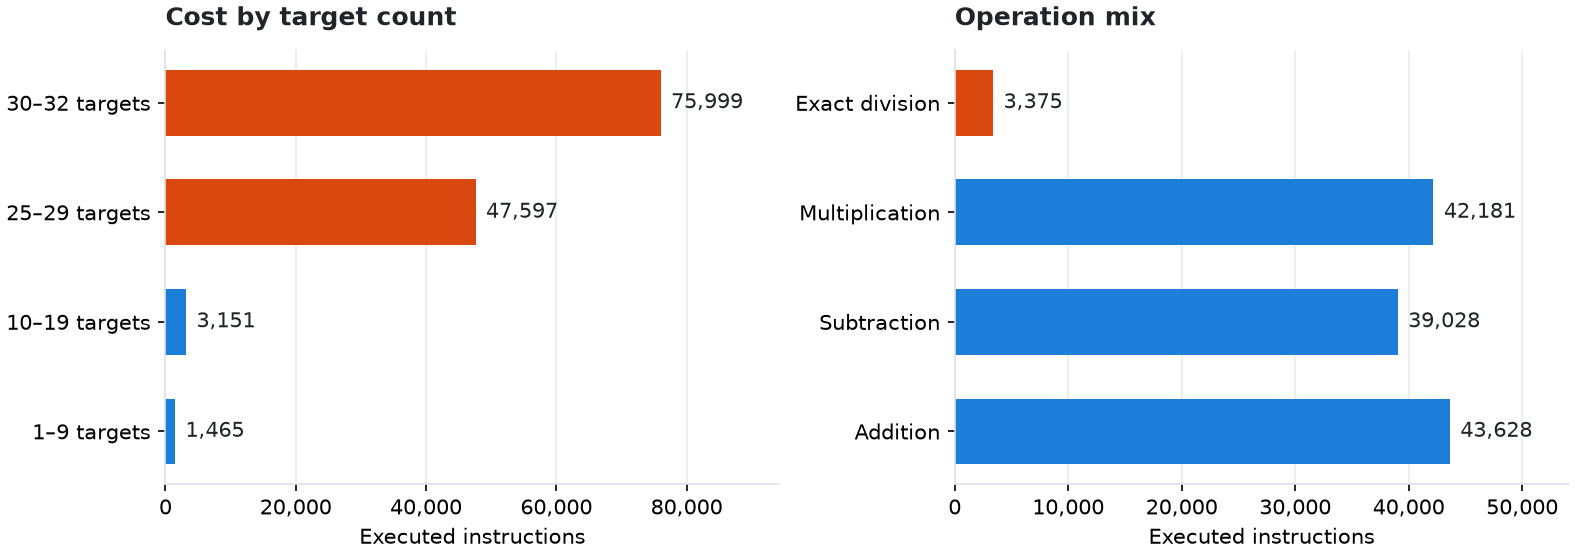

In [13]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter


class PortfolioFigures:
    @staticmethod
    def draw(puzzles, profiles):
        orange, blue = '#d9480f', '#1c7ed6'
        with plt.rc_context({
            'figure.facecolor': 'white', 'axes.spines.top': False,
            'axes.spines.right': False, 'axes.edgecolor': '#dee2e6',
            'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
            'text.color': '#212529', 'grid.color': '#e9ecef',
        }):
            fig, (cost, operations) = plt.subplots(1, 2, figsize=(10.5, 3.7), layout='constrained')
            bands = [(1, 9), (10, 19), (25, 29), (30, 32)]
            totals = [
                sum(profile.length for pid, profile in profiles.items()
                    if low <= len(puzzles[pid].targets) <= high)
                for low, high in bands
            ]
            assert sum(totals) == sum(profile.length for profile in profiles.values())
            counts = Counter()
            for profile in profiles.values():
                counts.update(profile.operations)

            def bars(ax, labels, values, colors, title):
                rectangles = ax.barh(labels, values, color=colors, height=.6)
                ax.bar_label(rectangles, labels=[f'{value:,}' for value in values], padding=5)
                ax.set_xlim(0, max(values)*1.24)
                ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
                ax.set_title(title, pad=12)
                ax.set_xlabel('Executed instructions')
                ax.grid(axis='x')
                ax.set_axisbelow(True)

            bars(cost, [f'{a}–{b} targets' for a, b in bands], totals,
                 [blue, blue, orange, orange], 'Cost by target count')
            bars(operations, ['Addition', 'Subtraction', 'Multiplication', 'Exact division'],
                 [counts[op] for op in '+-*/'], [blue, blue, blue, orange], 'Operation mix')
            plt.show()


PortfolioFigures.draw(PortfolioPipeline(Config.discover()).load_puzzles(), profiles)

## 6 · Local paired triwalk pilot

The pilot starts from the pinned 128,213 portfolio. Both arms use one shared 10-second CPU search, then a second 10-second search with the same seed in each arm. A verified shortening from the first pass becomes the starting program for both arms. Otherwise, the continuation arm starts from an equal-length variant if its arithmetic dependencies differ. When no such variant exists, the arms share the second result.

| Cohort | Puzzles | Different neutral graph | Restart savings | Continuation savings |
|:---|---:|---:|---:|---:|
| Recent | 30 | 20 | 0 | 0 |
| Matched | 30 | 22 | 0 | 1 |

Selecting the shorter verified program per puzzle saved **1** instruction. The notebook ships the verified replacements so export requires no timed search.